In [2]:
%pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 65.6 MB/s eta 0:00:00:00:01


In [3]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

extract_dir = Path("/content/unitochest")
zip_path = Path("/content/drive/MyDrive/unitochest.zip")

if not extract_dir.exists() or not any(extract_dir.rglob("*.dcm")):
    raise RuntimeError("Extraction did not look complete; zip was not deleted.")

zip_path.unlink()

In [ ]:
!cp -r /content/unitochest /content/drive/MyDrive/unitochest_extracted

helper show() function

In [6]:
def show(img, title=""):
    plt.figure(figsize=(6, 6))
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

load an example file

In [10]:
from pathlib import Path

base = Path("/content/drive/MyDrive")
matches = list(base.rglob("*.dcm"))
print("Found", len(matches), "dcm files")
for m in matches:
    print("-", m)

Found 1 dcm files
- /content/drive/MyDrive/1-01.dcm


In [13]:
import pydicom
from matplotlib import pyplot as plt

if not matches:
    raise FileNotFoundError(
        "No .dcm found under /content/drive/MyDrive — check location."
    )
p = matches[0]
dcm = pydicom.dcmread(str(p))
raw = dcm.pixel_array.astype("int16")

Convert to Hounsfield Units

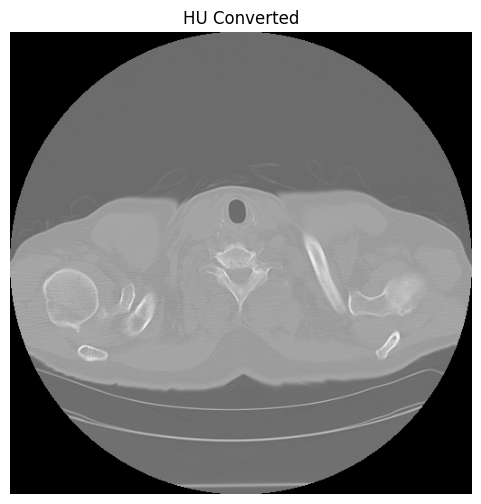

In [12]:
hu = raw * dcm.RescaleSlope + dcm.RescaleIntercept
show(hu, "HU Converted")

lung windowing

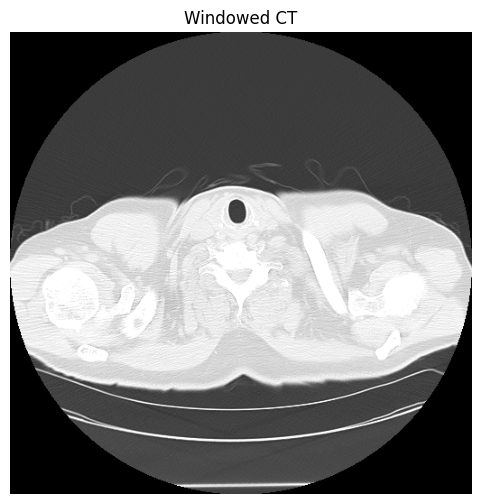

In [14]:
WL = -600
WW = 1500
lower = WL - WW // 2
upper = WL + WW // 2

windowed = np.clip(hu, lower, upper)
show(windowed, "Windowed CT")

resample to 1mm isotropic spacing

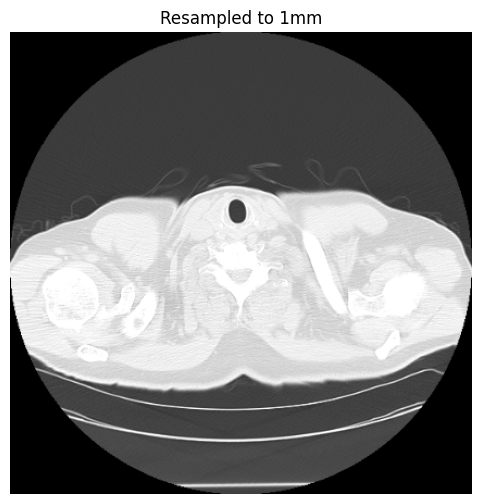

In [15]:
# Extract spacing from DICOM metadata
spacing = np.array([float(dcm.PixelSpacing[0]), float(dcm.PixelSpacing[1])])
slice_thickness = float(getattr(dcm, "SliceThickness", 1.0))

original_spacing = np.array([slice_thickness, *spacing])
new_spacing = np.array([1.0, 1.0, 1.0])

resize_factor = original_spacing / new_spacing
resampled = ndimage.zoom(windowed, resize_factor[1:], order=1)

show(resampled, "Resampled to 1mm")

normalise to [0,1]

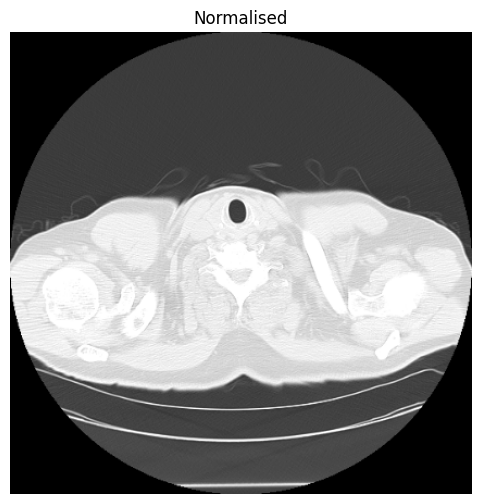

In [16]:
norm = (resampled - resampled.min()) / (resampled.max() - resampled.min())
show(norm, "Normalised")

blue overlay function

In [17]:
def overlay_blue(image, mask, alpha=0.4):
    img_rgb = np.stack([image, image, image], axis=-1)
    overlay = np.zeros_like(img_rgb)
    overlay[..., 2] = 1.0  # blue channel

    out = img_rgb.copy()
    out[mask == 1] = (1 - alpha) * img_rgb[mask == 1] + alpha * overlay[mask == 1]
    return out

test overlay with a fake mask

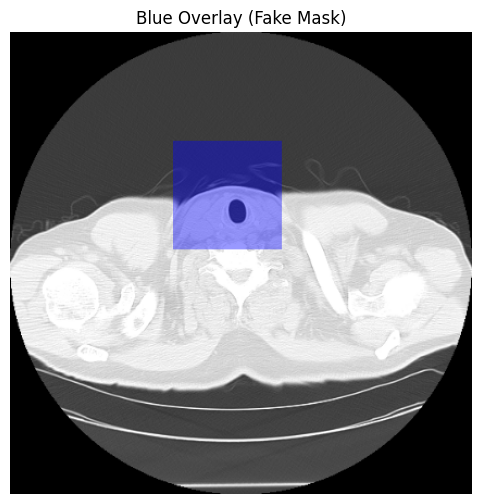

In [18]:
mask = np.zeros_like(norm)
mask[100:200, 150:250] = 1  # fake nodule region

highlighted = overlay_blue(norm, mask)
plt.figure(figsize=(6, 6))
plt.imshow(highlighted)
plt.title("Blue Overlay (Fake Mask)")
plt.axis("off")
plt.show()